# Calibration of a finite-strain hybrid model obtained by composition

This notebook illustrates the sequential composition of modules. A finite-strain model is
obtained by inserting a small-strain model $\mathcal{B}_{\boldsymbol\theta}$ in the behavior slot
of the logarithmic-strain metamodel, between a kinematic pre-processing $\mathcal{P}$ and a stress
post-processing $\mathcal{T}$:

$$
\mathcal{M}^\text{fin}_{\boldsymbol\theta} = \mathcal{T} \circ \mathcal{B}_{\boldsymbol\theta}
\circ \mathcal{P}, \qquad
\mathcal{P} : \boldsymbol F \mapsto \boldsymbol E_H = \tfrac{1}{2}\ln\boldsymbol C, \qquad
\mathcal{T} : (\boldsymbol T, \boldsymbol F) \mapsto \boldsymbol P = \boldsymbol F\,\bigl(2\,
\boldsymbol T : \partial\boldsymbol E_H/\partial\boldsymbol C\bigr),
$$

where $\boldsymbol C = \boldsymbol F^\text{T}\boldsymbol F$, $\boldsymbol E_H$ is the Hencky
strain, $\boldsymbol T$ its work-conjugate stress and $\boldsymbol P$ the first Piola-Kirchhoff
stress. Neither the small-strain model nor the wrapper is modified, and the parameters of the
composed model are those of the small-strain model.

The small-strain model is von Mises plasticity with a neural (ICNN-based) hardening law. The
composed model is calibrated as a finite-strain model on a tension test on a structural steel:
the loss compares the Cauchy stress of the composed model, under uniaxial stress along the
measured strain history, with the measured true stress. Its gradient is obtained by automatic
differentiation through the whole chain: tensor logarithm, return mapping, neural hardening law,
stress post-processing and lateral stress-free condition. Two properties of the calibrated model
are then verified: objectivity, which follows from $\mathcal{P}$, and the exactness of the
consistent tangent $\partial\boldsymbol P/\partial\boldsymbol F$.

In [1]:
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optimistix as optx
import paramax

import jaxmat
import jaxmat.materials as jm
from jaxmat.nn.icnn import ICNN
from jaxmat.tensors import Tensor2, rotation
from jaxmat.utils import partition_by_node_names

print(
    f"jaxmat {jaxmat.__version__}, jax {jax.__version__}, float64: {jax.config.jax_enable_x64}"
)

MODEL = dict(color="royalblue", ls="-", lw=2.0)

jaxmat 0.1, jax 0.10.2, float64: True


## Data

The data is a monotonic tension test on a structural steel, given as true stress versus true
strain up to the onset of necking. It is distributed as an example with RESSPyLab
(de Castro e Sousa et al., MIT license), together with two cyclic tests. A
database of such coupon tests is available on Zenodo (Hartloper et al., 2022,
doi:10.5281/zenodo.6965147) and through the RESSLab-hub web application of EPFL. The test shows
a yield plateau at about 320 MPa, up to a strain of about 2%, followed by strain hardening. The
points after the maximum stress are discarded.

In [2]:
data = np.genfromtxt("tension_test.csv", delimiter=",", skip_header=1)
last = int(np.argmax(data[:, -1]))
eps_test, sig_test = jnp.asarray(data[: last + 1, 0]), jnp.asarray(data[: last + 1, -1])
print(
    f"{len(eps_test)} points, true strain up to {float(eps_test[-1]):.3f}, "
    f"true stress up to {float(sig_test[-1]):.0f} MPa"
)

332 points, true strain up to 0.123, true stress up to 530 MPa


## Composed model

**Small-strain model.** Von Mises plasticity with isotropic linear elasticity and isotropic
hardening (`vonMisesIsotropicHardening`). The hardening law derives from a scalar ICNN $\psi$
with one hidden layer of 5 units,

$$
\sigma_y(p) = \sigma_\text{ref}\,\psi'(p/p_\text{ref}), \qquad p_\text{ref} = 0.1, \quad
\sigma_\text{ref} = 1000~\text{MPa},
$$

and is non-decreasing by construction. The Young modulus is calibrated together with the network
weights, through the positive parametrization $E = \exp(z)$ starting from $E = 200$ GPa; the
Poisson ratio is fixed at $\nu = 0.3$. The network is randomly initialized. The return mapping is
solved by Newton's method (`optimistix`).

**Composition.** The small-strain model is wrapped by `LogarithmicStrain`, which implements
$\mathcal{P}$ and $\mathcal{T}$.

In [3]:
p_ref, sig_ref, width = 0.1, 1e3, 5


class ICNNHardening(eqx.Module):
    potential: ICNN

    def __call__(self, p):
        return sig_ref * jax.grad(self.potential)(p / p_ref)


elasticity = jm.LinearElasticIsotropic(E=200e3, nu=0.3)
elasticity = eqx.tree_at(
    lambda e: e.E,
    elasticity,
    paramax.Parameterize(jnp.exp, jnp.log(jnp.asarray(200e3))),
)
small_strain_model = jm.vonMisesIsotropicHardening(
    elasticity=elasticity,
    yield_stress=ICNNHardening(ICNN(0, [width], jax.random.key(0))),
    solver=optx.Newton(rtol=1e-6, atol=1e-8),
)
model_initial = jm.LogarithmicStrain(small_strain_model)  # the composition

params, static = partition_by_node_names(model_initial, ["behavior.elasticity.nu"])
n_params = sum(
    x.size for x in jax.tree.leaves(eqx.filter(params, eqx.is_inexact_array))
)
print(
    f"Calibrated parameters: {n_params} (E and the network weights); initial "
    f"sigma_y(0) = {float(small_strain_model.yield_stress(0.0)):.0f} MPa"
)

Calibrated parameters: 17 (E and the network weights); initial sigma_y(0) = 1620 MPa


## Uniaxial stress along the measured history

The deformation gradient is $\boldsymbol F = \operatorname{diag}(\lambda, u, u)$, with the axial
stretch $\lambda = \exp\varepsilon$ imposed along the measured history. At each increment, the
lateral stretch $u$ is the solution of $P_{22}(u) = 0$ ($P_{33} = P_{22}$ by isotropy), solved by
Newton's method (`optimistix`) and differentiated by the implicit function theorem. The Cauchy
stress is $\sigma_{11} = P_{11}/u^2$. The increments are chained by `jax.lax.scan`.

In [4]:
lateral_solver = optx.Newton(rtol=1e-6, atol=1e-8)


def uniaxial_stress(model, stretches):
    """Cauchy stress, cumulated plastic strain and lateral stretch along an axial stretch history."""
    model = paramax.unwrap(model)

    def F_of(lam, u):
        return Tensor2(tensor=jnp.diag(jnp.stack([lam, u, u])))

    def step(carry, lam):
        state, u = carry

        def residual(u, _):
            return (
                model.constitutive_update(F_of(lam, u), state, 0.0)[0].tensor[1, 1]
                / sig_ref
            )

        sol = optx.root_find(
            residual,
            lateral_solver,
            u,
            adjoint=optx.ImplicitAdjoint(),
            max_steps=50,
            throw=False,
        )
        u = sol.value
        P, state = model.constitutive_update(F_of(lam, u), state, 0.0)
        return (state, u), (P.tensor[0, 0] / u**2, state.internal.p, u)

    _, (sig, p, u) = jax.lax.scan(
        step, (model.init_state(), jnp.asarray(1.0)), stretches
    )
    return sig, p, u


@eqx.filter_jit
def simulate(model):
    sig, p, u = uniaxial_stress(model, jnp.exp(eps_test[1:]))
    return jnp.concatenate([jnp.zeros(1), sig]), jnp.concatenate([jnp.zeros(1), p]), u

## Calibration

The error measure is that of RESSPyLab: the squared stress error weighted by the strain
increments, normalized by the same weighting of the squared measured stress,

$$
\varphi(\boldsymbol\theta) = \frac{\sum_i |\Delta\varepsilon_i|\,
\bigl[(\sigma_i - \sigma_i^\text{exp})^2 + (\sigma_{i-1} - \sigma_{i-1}^\text{exp})^2\bigr]}
{\sum_i |\Delta\varepsilon_i|\,\bigl[(\sigma_i^\text{exp})^2 + (\sigma_{i-1}^\text{exp})^2\bigr]},
$$

so that the loss does not depend on the density of the data points along the curve, which is
much higher on the yield plateau. A weight decay
$\lambda\,\|\boldsymbol\theta_\text{NN}\|_2^2/n_\text{NN}$ with $\lambda = 10^{-6}$ is added.
The optimizer is BFGS.

In [5]:
gamma_wd = 1e-6  # weight decay (lambda in the text)


def phi(sig_model, eps, sig_exp):
    w = jnp.abs(jnp.diff(eps))
    err = jnp.sum(
        w * ((sig_model[1:] - sig_exp[1:]) ** 2 + (sig_model[:-1] - sig_exp[:-1]) ** 2)
    )
    return err / jnp.sum(w * (sig_exp[1:] ** 2 + sig_exp[:-1] ** 2))


def weight_decay(model):
    leaves = jax.tree.leaves(
        eqx.filter(model.behavior.yield_stress, eqx.is_inexact_array)
    )
    return sum(jnp.sum(x**2) for x in leaves) / sum(x.size for x in leaves)


def loss(params, args=None):
    model = eqx.combine(params, static)
    return phi(simulate(model)[0], eps_test, sig_test) + gamma_wd * weight_decay(model)


sol = optx.minimise(
    loss, optx.BFGS(rtol=1e-6, atol=1e-8), params, max_steps=2000, throw=False
)
model = paramax.unwrap(eqx.combine(sol.value, static))
hardening = model.behavior.yield_stress
print(
    f"BFGS iterations: {int(sol.stats['num_steps'])}, "
    f"converged: {bool(sol.result == optx.RESULTS.successful)}"
)

sig_model, p_model, u_model = simulate(model)
print(
    f"E = {1e-3 * float(model.behavior.elasticity.E):.1f} GPa, "
    f"phi = {100 * float(phi(sig_model, eps_test, sig_test)):.3f}%, "
    f"sigma_y(0) = {float(hardening(0.0)):.1f} MPa, "
    f"sigma_y(p_end) = {float(hardening(p_model[-1])):.1f} MPa, p_end = {float(p_model[-1]):.3f}"
)

BFGS iterations: 1034, converged: True
E = 202.5 GPa, phi = 0.008%, sigma_y(0) = 312.0 MPa, sigma_y(p_end) = 527.6 MPa, p_end = 0.121


Relative error on the stress along the plastic branch, by segment of the curve:

In [6]:
rel = np.abs(np.asarray(sig_model - sig_test))[1:] / np.asarray(sig_test)[1:]
eps_np, plastic = np.asarray(eps_test)[1:], np.asarray(p_model)[1:] > 1e-4
for segment, (lo, hi) in {
    "yield plateau": (0.0, 0.019),
    "end of plateau": (0.019, 0.03),
    "hardening": (0.03, 1.0),
}.items():
    sel = plastic & (eps_np >= lo) & (eps_np < hi)
    print(
        f"{segment:15s} ({sel.sum():3d} points): mean {100 * rel[sel].mean():.2f}%, "
        f"max {100 * rel[sel].max():.1f}%"
    )

yield plateau   (234 points): mean 1.23%, max 6.2%
end of plateau  ( 28 points): mean 4.39%, max 8.2%
hardening       ( 40 points): mean 0.28%, max 0.8%


Each figure below is also saved as a PDF and a PNG file.

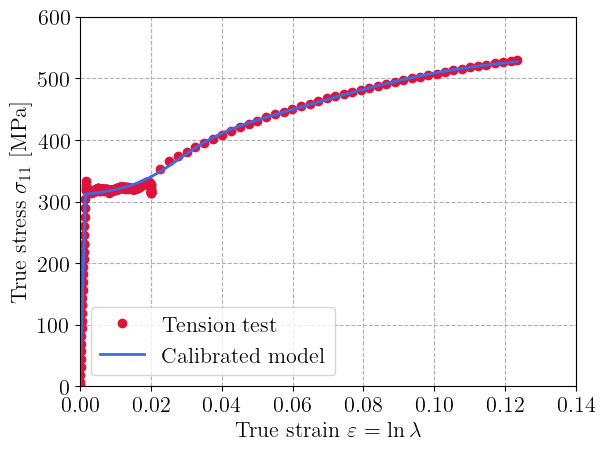

In [7]:
fig, ax = plt.subplots()
ax.plot(eps_test, sig_test, "o", color="crimson", label="Tension test")
ax.plot(eps_test, sig_model, label="Calibrated model", **MODEL)
ax.set_xlabel(r"True strain $\varepsilon = \ln\lambda$")
ax.set_ylabel(r"True stress $\sigma_{11}$ [MPa]")
ax.legend()
for ext in ("pdf", "png"):
    fig.savefig(f"tension_test.{ext}", bbox_inches="tight")
plt.show()

The next figure shows the calibrated hardening law against the pairs
$(\varepsilon - \sigma/E, \sigma)$ of the plastic branch, computed from the data with the
calibrated $E$. These pairs are not used in the calibration, which only involves the response of
the composed model: under uniaxial stress, the composed model reduces to $\tau = \sigma_y(p)$
and $\ln\lambda = \tau/E + p$, where $\tau = J\sigma$ is the Kirchhoff stress and
$J - 1 = (1 - 2\nu)\,\tau/E$ remains small (printed below).

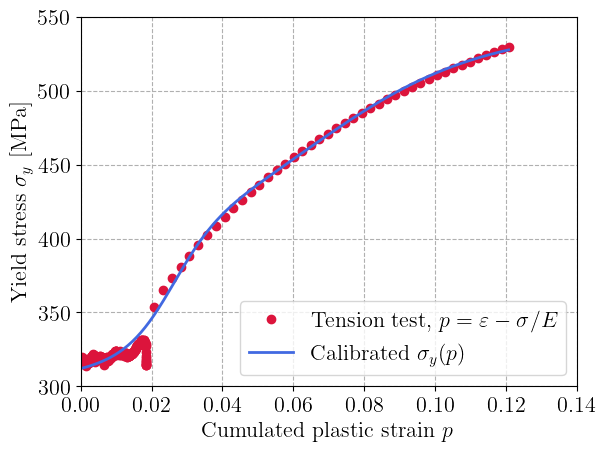

Maximum of J - 1 along the test: 1.0e-03


In [8]:
p_plot = jnp.linspace(0.0, float(p_model[-1]), 300)
p_exp = eps_test - sig_test / model.behavior.elasticity.E
on_yield = p_exp > 2e-4  # points of the plastic branch
fig, ax = plt.subplots()
ax.plot(
    p_exp[on_yield],
    sig_test[on_yield],
    "o",
    color="crimson",
    label=r"Tension test, $p = \varepsilon - \sigma/E$",
)
ax.plot(p_plot, jax.vmap(hardening)(p_plot), label=r"Calibrated $\sigma_y(p)$", **MODEL)
ax.set_xlim(0, None)
ax.set_xlabel("Cumulated plastic strain $p$")
ax.set_ylabel(r"Yield stress $\sigma_y$ [MPa]")
ax.legend()
for ext in ("pdf", "png"):
    fig.savefig(f"finite_strain_hardening.{ext}", bbox_inches="tight")
plt.show()

J = jnp.exp(eps_test[1:]) * u_model**2
print(f"Maximum of J - 1 along the test: {float(jnp.max(J - 1.0)):.1e}")

## Objectivity

A time-dependent rigid rotation $\boldsymbol Q_k$ is superposed on a general deformation path
$\boldsymbol F_k = \boldsymbol I + (k/n)\,\boldsymbol G$, $k = 1,\dots,n$, with stretch and
shear, which remains within the range of cumulated plastic strain of the tension test. The
rotation has a random axis and an angle increasing linearly from 0 to $2\pi$ along the path.
Objectivity requires $\boldsymbol P(\boldsymbol Q_k\boldsymbol F_k) =
\boldsymbol Q_k\,\boldsymbol P(\boldsymbol F_k)$ and identical internal variables. The test is
repeated for 200 random axes, evaluated in one batched (`vmap`) computation.

In [9]:
n_path = 50
G = 0.2 * jnp.array([[0.6, 0.3, 0.0], [0.1, -0.25, 0.15], [0.0, 0.05, -0.2]])
F_path = jnp.eye(3) + jnp.linspace(1.0 / n_path, 1.0, n_path)[:, None, None] * G
angles = jnp.linspace(2 * jnp.pi / n_path, 2 * jnp.pi, n_path)


def path_response(material, F_path):
    def step(state, F):
        P, state = material.constitutive_update(Tensor2(tensor=F), state, 0.0)
        return state, (P.tensor, state.internal.p)

    return jax.lax.scan(step, material.init_state(), F_path)[1]


@eqx.filter_jit
def objectivity_error(material, axis):
    Q = jax.vmap(lambda a: rotation.from_axis_angle(axis, a))(angles)
    P, p = path_response(material, F_path)
    P_rot, p_rot = path_response(material, Q @ F_path)
    err_P = jnp.max(
        jnp.linalg.norm(P_rot - Q @ P, axis=(1, 2)) / jnp.linalg.norm(P, axis=(1, 2))
    )
    return err_P, jnp.max(jnp.abs(p_rot - p))


axes = jax.random.normal(jax.random.key(1), (200, 3))
axes = axes / jnp.linalg.norm(axes, axis=1, keepdims=True)
err_P, err_p = eqx.filter_vmap(objectivity_error, in_axes=(None, 0))(model, axes)
_, p_path = path_response(model, F_path)
print(
    f"Max relative error on P: {float(err_P.max()):.1e}, max error on p: {float(err_p.max()):.1e}"
)
print(f"Cumulated plastic strain at the end of the path: {float(p_path[-1]):.3f}")

Max relative error on P: 4.2e-13, max error on p: 4.7e-16
Cumulated plastic strain at the end of the path: 0.116


## Consistent tangent: Taylor test

The consistent tangent $\mathbb{A} = \partial\boldsymbol P_{n+1}/\partial\boldsymbol F_{n+1}$,
at fixed state $n$, is obtained by forward-mode automatic differentiation of the whole
composition. For a random direction $\delta\boldsymbol F$ of unit norm, the Taylor remainder

$$
r(h) = \bigl\|\boldsymbol P(\boldsymbol F + h\,\delta\boldsymbol F) - \boldsymbol P(\boldsymbol F)
- h\,\mathbb{A}:\delta\boldsymbol F\bigr\|
$$

decreases as $h^2$ if $\mathbb{A}$ is exact. The test is performed at three states:

- **identity:** $\boldsymbol F = \boldsymbol I$ from the initial state (elastic, three equal
  principal stretches);
- **uniaxial, plastic:** a plastic increment of the tension test, at a true strain of about 0.08
  (two equal principal stretches);
- **general, plastic:** a plastic increment of the path of the objectivity test (distinct
  principal stretches).

The derivatives of the tensor logarithm are defined in closed form (divided differences of the
eigenvalues), so that they remain exact at repeated eigenvalues. The perturbation size is
limited to $h \geq 10^{-6}$: for smaller perturbations of a tensor with repeated eigenvalues, the
remainder reaches the round-off level of the closed-form eigendecomposition.

In [10]:
def taylor_remainders(material, F, state, dF, hs):
    def P_of(F_array):
        return material.constitutive_update(Tensor2(tensor=F_array), state, 0.0)[
            0
        ].tensor

    P0 = P_of(F)
    AdF = jnp.einsum("ijkl,kl->ij", jax.jacfwd(P_of)(F), dF)
    return np.array(
        [float(jnp.linalg.norm(P_of(F + h * dF) - P0 - h * AdF)) for h in hs]
    )


def state_before(material, F_steps):
    state = material.init_state()
    for F in F_steps:
        _, state = material.constitutive_update(Tensor2(tensor=F), state, 0.0)
    return state


i_test = int(np.argmin(np.abs(np.asarray(eps_test) - 0.08)))
F_test = [
    jnp.diag(jnp.stack([jnp.exp(eps_test[k]), u_model[k - 1], u_model[k - 1]]))
    for k in range(1, i_test + 1)
]
cases = {
    "Identity (elastic)": (jnp.eye(3), model.init_state()),
    "Uniaxial (plastic)": (F_test[-1], state_before(model, F_test[:-1])),
    "General (plastic)": (F_path[25], state_before(model, F_path[:25])),
}
dF = jax.random.normal(jax.random.key(3), (3, 3))
dF = dF / jnp.linalg.norm(dF)
hs = np.logspace(-1, -6, 21)
remainders = {
    name: taylor_remainders(model, F, st, dF, hs) for name, (F, st) in cases.items()
}

sel = hs <= 1e-4
for name, (F, st) in cases.items():
    stretches = np.sqrt(np.linalg.eigvalsh(np.asarray(F).T @ np.asarray(F)))
    slope = np.polyfit(np.log(hs[sel]), np.log(remainders[name][sel]), 1)[0]
    print(
        f"{name:20s} principal stretches {stretches.round(4)}, "
        f"p_n = {float(st.internal.p):.3f}, slope on [1e-6, 1e-4]: {slope:.2f}"
    )

Identity (elastic)   principal stretches [1. 1. 1.], p_n = 0.000, slope on [1e-6, 1e-4]: 1.99
Uniaxial (plastic)   principal stretches [0.9616 0.9616 1.0825], p_n = 0.075, slope on [1e-6, 1e-4]: 2.00
General (plastic)    principal stretches [0.963  0.9855 1.0672], p_n = 0.058, slope on [1e-6, 1e-4]: 2.00


From the identity, the largest perturbations exceed the elastic domain, whose extent is set by the
uniaxial yield strain $\sigma_y(0)/E$. The response is then no longer smooth in $h$, which
explains the jump in the remainder.

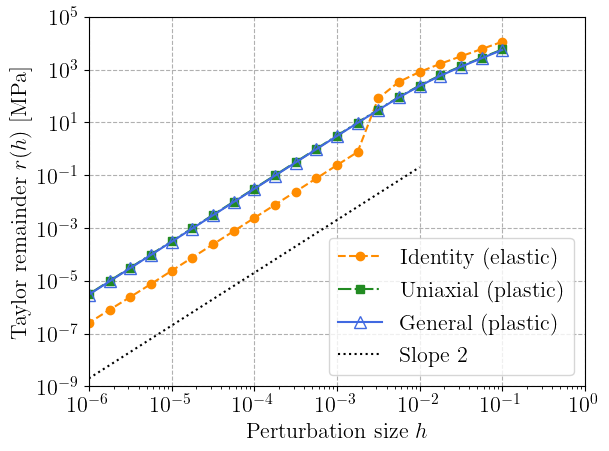

In [11]:
TAYLOR_STYLE = {
    "Identity (elastic)": dict(color="darkorange", ls="--", marker="o"),
    "Uniaxial (plastic)": dict(color="forestgreen", ls="-.", marker="s"),
    "General (plastic)": dict(color="royalblue", ls="-", marker="^", mfc="none", ms=9),
}
fig, ax = plt.subplots()
for name, r in remainders.items():
    ax.loglog(hs, r, lw=1.5, label=name, **TAYLOR_STYLE[name])
h_ref = np.array([1e-6, 1e-2])
ax.loglog(h_ref, 2e3 * h_ref**2, color="black", ls=":", lw=1.5, label="Slope 2")
ax.set_xlabel("Perturbation size $h$")
ax.set_ylabel("Taylor remainder $r(h)$ [MPa]")
ax.legend()
for ext in ("pdf", "png"):
    fig.savefig(f"taylor_test.{ext}", bbox_inches="tight")
plt.show()

## Discussion

The values printed above are reported and discussed in the accompanying paper (section "Finite
strain by composition: calibration of a wrapped hybrid model").

The hardening law of the small-strain model and the Young modulus are calibrated through the
composed finite-strain model, from a randomly initialized network, without any change to the
small-strain model, to the wrapper or to the calibration code. The loss only involves the
response of the composed model under mixed control, and its gradient is obtained by automatic
differentiation through the tensor logarithm, the implicit return mapping, the neural hardening
law, the stress post-processing and the implicit lateral stress-free condition.

The calibrated model follows the hardening branch closely. The largest deviations occur at the
end of the yield plateau, where the measured stress drops at constant strain, which a
rate-independent model cannot represent, and then rises abruptly. The upper yield point and the
oscillations of the stress along the plateau are not represented either, since $\sigma_y$ is
non-decreasing by construction. The calibrated hardening law agrees with the pairs
$(\varepsilon - \sigma/E, \sigma)$ computed from the data, which are not used in the calibration.

Under time-dependent superposed rotations, the stress transforms as
$\boldsymbol P \to \boldsymbol Q\boldsymbol P$ and the internal variables are unchanged, to
machine precision. This property follows from the pre-processing $\mathcal{P}$, which depends on
$\boldsymbol F$ only through $\boldsymbol C$, and holds for any small-strain model inserted in
the behavior slot, here a model with a neural hardening law.

The Taylor remainders decrease with slope 2 at the three states, as long as the perturbation does
not cross the yield surface, including the states with two and three equal principal stretches.
The tangent is obtained by automatic differentiation of the whole composition, without
model-specific derivation.